# Closed-loop feedback on an emulated camera: the updates of Nogrette and of Kim

**Question:** What do the two published camera updates, Nogrette's reweighting and Kim's square-root update, make of a hologram that looks uniform in the model and 19 percent uneven to the camera, and do they reproduce the published end points on the emulated camera?

- Level: 3, state of the art. Method run: M12.
- Prerequisites: `03-gerchberg-saxton/02-weights-for-uniformity` for the weighted loop, and `01-fourier-optics/02-reading-a-trap-array` for the spread of the traps.
- Reading time: about 30 minutes. The notebook runs in about a minute and a half.

## Objectives

A hologram that is uniform on paper is not uniform in the experiment: the real light differs from the model by aberrations, by the response of the device, by an imperfect beam. Experiments close the loop with a camera: they look at the traps, find which are brighter and which dimmer, change the target weights, recompute and look again. M12 implements the two published ways of doing that, on a camera whose errors are stated parameters. By the end you can:

- say what the emulated camera reports and why the report and the model's intensities disagree by construction;
- run the update of Nogrette et al. and the update of Kim et al. on the same camera and read their curves;
- say what the number of Gerchberg-Saxton iterations between two measurements does to the loop;
- compare both loops with the best open-loop hologram read by the same camera;
- compare the end points with the published ones over three draws of the camera, and read how the loop depends on the gain of the update and on the noise of the camera.

## Setup


The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` on Windows). This notebook uses two packages, at these exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in the pipeline folder `data-pipeline/`, and the next cell puts
that folder on the import path and imports the functions the notebook calls.

In [1]:
# the tools, their versions, and the pipeline folder on the import path
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.camera import EmulatedCamera
from pipeline.model.holo.core.forward import fft_focal_field
from pipeline.model.holo.core.metrics import rel_std, trap_intensities
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.control import m12_closed_loop

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Data

The notebook reads case C02 of `data/examples/cases.json`: the 10 x 10 task of the optimisation topic with a feedback block (a gain of 0.7, 20 steps and a camera whose per-trap gain error is 0.19).

- Owner: this repository; the case is synthetic, and the camera parameters of the record follow the 19 percent open-loop spread that Nogrette et al. report.
- Licence class: generated data under the repository's own licence, no third-party dataset.
- File: `data/examples/cases.json`, case C02.

In [2]:
# case C02: the 10 x 10 task with a feedback block (gain 0.7, 20 steps, camera gain error 0.19)
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C02"]
setup = build.setup_of(rec)
target = build.target_of(rec)
traps = target.traps
feedback = rec["feedback"]
print(rec["case_id"], "|", len(traps), "traps | feedback:", feedback)

C02_grid_feedback | 100 traps | feedback: {'gain': 0.7, 'steps': 20, 'camera': {'gain_rms': 0.19, 'noise_rms': 0.0, 'blur_bins': 0.0}}


## Method

### The emulated camera, and what it reports

The emulated camera of the pipeline gives each trap a fixed multiplicative gain $g_m = \exp(s z_m - s^2/2)$ with $z_m$ a standard normal draw seeded by the camera and the trap, so that the gains are log-normal with mean 1 and a relative rms of about $s = 0.19$. It adds optional Gaussian noise and blur, and it never changes between measurements: a trap that reads 20 percent too bright keeps doing so. This is an emulation, not a model of a sensor: the gain stands for everything that separates the real light from the model's intensity $I_m$, and the camera reports $g_m I_m$. The experimenter sees only the report. The first cell computes a weighted-GS hologram for the 10 x 10 task (30 iterations) and compares what the model says with what the camera reports.

In [3]:
# what the camera sees of a good hologram: weighted GS, 30 iterations, read through an emulated camera
res0 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1))
camera = EmulatedCamera(seed=101, gain_rms=feedback["camera"]["gain_rms"], noise_rms=0.0, rolloff=False)
true_i = trap_intensities(res0.fields)
seen_i = camera.measure(fft_focal_field(res0.phi, setup), setup, traps)
print(f"spread of the true intensities: {rel_std(true_i):.2f} %")
print(f"spread of the intensities the camera reports: {rel_std(seen_i):.2f} %")
print("gains of the first five traps:", [round(camera.gain(int(i)), 3) for i in traps.ids[:5]])

spread of the true intensities: 0.84 %
spread of the intensities the camera reports: 19.46 %
gains of the first five traps: [0.907, 0.802, 0.77, 0.91, 1.26]


The scatter plots the reported intensity of each of the 100 traps against the model's, both relative to their means, with the identity line.

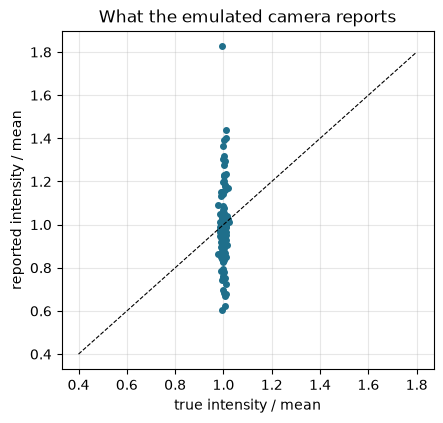

In [4]:
# the intensity the camera reports against the true one, trap by trap, relative to the mean
fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.plot(true_i / true_i.mean(), seen_i / seen_i.mean(), "o", markersize=4, color="#1f6f8b")
ax.plot([0.4, 1.8], [0.4, 1.8], "k--", linewidth=0.8)
ax.set_xlabel("true intensity / mean")
ax.set_ylabel("reported intensity / mean")
ax.set_title("What the emulated camera reports")
ax.grid(True, alpha=0.3)
plt.show()

The model says the traps are equal to within 0.84 percent, and the camera reports a spread of 19.46 percent: the first five gains printed above range from 0.77 to 1.26. In the figure the points lie on a horizontal band, not on the diagonal: the model's intensities are nearly all the same, and the reported ones spread over a range of about 0.6 to 1.5 of the mean. This is the situation of the experiment, and it fixes what the loop can and cannot do. It can make what the camera reports uniform, which is the quantity the published curves plot. It cannot make the model's own intensities more uniform, and it will not: if the camera reads a trap 25 percent high, the loop lowers that trap until the report is equal, and the model's intensity there becomes 20 percent too low. The figure does not show noise, blur or a roll-off of the camera, which the camera can add and this notebook leaves at zero.

## State of the art

Two published loops are the state of the art, and M12 implements both. Nogrette et al. (2014) measure the trap intensities, rescale each trap's target by $1 / (1 - G(1 - \rho_m))$ with $\rho_m$ the measured intensity relative to the mean and $G$ the gain, and run one Gerchberg-Saxton iteration from the current hologram; the paper reports a spread falling from 19 percent rms to 1.4 percent in 20 iterations at $G = 0.7$. Kim et al. (2019) rescale by the square root of the mean over the measured intensity at full gain, freeze the focal phase of the current hologram, and report 22 percent falling to 1.59 percent in three steps. A comparison with the feedback mode of slmsuite was not run: it expects a camera of its own interface, and the notebook did not build that adapter, so whether its API allows it with this emulation is UNVERIFIED. The baseline is the best open-loop hologram, M07, read by the same camera. The first cell runs the loop of Nogrette for 20 iterations on three draws of the camera, and compares the end points with the published ones.

In [5]:
# the loop of Nogrette et al.: gain 0.7, 20 feedback iterations, three camera draws
nogrette = {}
for seed in (1, 2, 3):
    cam = EmulatedCamera(seed=100 + seed, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    nogrette[seed] = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(seed), camera=cam)
for seed, res in nogrette.items():
    spread = [h["rel_std"] for h in res.history]
    print(f"camera draw {seed}: open loop {res.meta['open_loop_rel_std']:.2f} % | "
          f"step 3 {spread[2]:.2f} % | step 20 {spread[19]:.2f} % | "
          f"model-side spread at step 20 {res.history[19]['rel_std_true']:.2f} %")

camera draw 1: open loop 19.46 % | step 3 8.26 % | step 20 1.41 % | model-side spread at step 20 19.35 %
camera draw 2: open loop 18.25 % | step 3 6.89 % | step 20 1.03 % | model-side spread at step 20 18.43 %
camera draw 3: open loop 19.24 % | step 3 6.65 % | step 20 0.95 % | model-side spread at step 20 18.98 %


The measured spread falls from 19.46 percent to 8.26 at step 3, 4.16 at step 5 and 1.41 at step 20, which is the published 1.4 percent. It is not monotone: it is 4.41 percent at step 10, higher than at step 5. The documentation of M12 gives a likely reason, that each inner Gerchberg-Saxton iteration reintroduces the algorithm's own unevenness between two measurements. The cell tests it by running the same loop with three inner iterations instead of one.

In [6]:
# the same loop with three Gerchberg-Saxton iterations between two measurements instead of one
cam1b = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
nog3 = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam1b, n_inner=3)
spread_nog3 = [h["rel_std"] for h in nog3.history]
picked = " ".join(f"{spread_nog3[k]:.2f}" for k in (2, 4, 9, 19))
print(f"n_inner = 3: steps 3, 5, 10, 20: {picked} %")

n_inner = 3: steps 3, 5, 10, 20: 7.73 7.30 3.56 5.23 %


With the gain of 0.7 the measured spread of the three draws falls from 19.46, 18.25 and 19.24 percent to 1.41, 1.03 and 0.95 percent at step 20, which is the published 1.4 percent or better, and is 8.26, 6.89 and 6.65 percent at step 3. The second loop is the one of Kim et al., run from a plain GS start for three steps.

In [7]:
# the variant of Kim et al.: square-root weights, full gain, three feedback steps, from a plain GS start
kim = {}
for seed in (1, 2, 3):
    cam = EmulatedCamera(seed=100 + seed, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    kim[seed] = m12_closed_loop.run(setup, target, budget=Budget(3), rng=Rng(seed), camera=cam,
                                    variant="kim", start="gs")
for seed, res in kim.items():
    spread = [h["rel_std"] for h in res.history]
    print(f"camera draw {seed}: open loop {res.meta['open_loop_rel_std']:.2f} % | "
          f"steps 1 to 3 {spread[0]:.2f} {spread[1]:.2f} {spread[2]:.2f} %")

camera draw 1: open loop 28.29 % | steps 1 to 3 13.59 2.89 1.12 %
camera draw 2: open loop 26.06 % | steps 1 to 3 14.04 2.47 1.26 %
camera draw 3: open loop 27.77 % | steps 1 to 3 15.09 3.63 1.70 %


The loop of Kim starts higher (28.29, 26.06 and 27.77 percent), because a plain GS start is itself uneven and the camera adds its own spread, and falls to 1.12, 1.26 and 1.70 percent in three steps, around the published 1.59 percent. For the baseline without feedback, the cell reads the phase-fixed WGS hologram M07 through a camera with the same gains.

In [8]:
# the baseline without feedback: phase-fixed WGS (M07), the best open-loop hologram, read by the same camera
res07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1))
cam_open = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
seen07 = cam_open.measure(fft_focal_field(res07.phi, setup), setup, traps)
print(f"M07: spread of the true intensities {rel_std(trap_intensities(res07.fields)):.2f} % | "
      f"spread the camera reports {rel_std(seen07):.2f} %")

M07: spread of the true intensities 0.01 % | spread the camera reports 19.41 %


The curves of the six runs are drawn together with the two published end points.

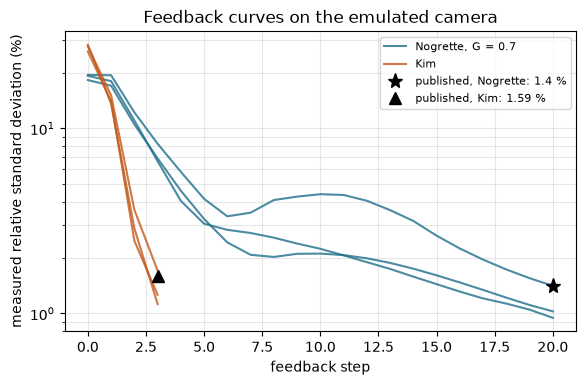

In [9]:
# measured spread against feedback step for both loops, with the published end points
fig, ax = plt.subplots(figsize=(6.6, 3.9))
for seed, res in nogrette.items():
    steps = [0, *[h["iteration"] for h in res.history]]
    spread = [res.meta["open_loop_rel_std"], *[h["rel_std"] for h in res.history]]
    ax.semilogy(steps, spread, color="#1f6f8b", alpha=0.8, label="Nogrette, G = 0.7" if seed == 1 else None)
for seed, res in kim.items():
    steps = [0, *[h["iteration"] for h in res.history]]
    spread = [res.meta["open_loop_rel_std"], *[h["rel_std"] for h in res.history]]
    ax.semilogy(steps, spread, color="#c2571a", alpha=0.8, label="Kim" if seed == 1 else None)
ax.plot([20], [1.4], "k*", markersize=11, label="published, Nogrette: 1.4 %")
ax.plot([3], [1.59], "k^", markersize=9, label="published, Kim: 1.59 %")
ax.set_xlabel("feedback step")
ax.set_ylabel("measured relative standard deviation (%)")
ax.set_title("Feedback curves on the emulated camera")
ax.legend(fontsize=8)
ax.grid(True, which="both", alpha=0.3)
plt.show()

The Kim loop starts higher, 28.29, 26.06 and 27.77 percent, because a plain GS start is itself uneven and the camera adds its own spread on top, where the published start is 22 percent. It falls to 13.59, 14.04 and 15.09 percent after one step, and to 1.12, 1.26 and 1.70 percent after three, around the published 1.59 percent. The Nogrette loop needs 17 steps to reach the level that Kim reaches in three, and its curve is not monotone: two of the three draws have a plateau or a rise between steps 6 and 12, before the fall resumes. The pipeline's own documentation of M12 gives a likely reason, that each inner Gerchberg-Saxton iteration reintroduces the algorithm's own unevenness between two measurements, but the notebook did not isolate it. The figure shows agreement of the end points; it does not show that the curves agree in between, because the published curves are not available as data here, and it does not show a camera other than the one emulated. The best open-loop hologram, M07, is equal to 0.01 percent in the model and is read as 19.41 percent by the same camera, the level where every loop starts: no amount of open-loop computation can know the gains.

### What the emulator adds: the gain of the update and the noise of the camera

The agreement with the published end points has two limits that should be said. The 19 percent open-loop spread was chosen as the camera's gain error because the paper reports it, so the starting point agrees by construction and only the closed-loop result is a test; and one camera emulates one published camera, so the agreement shows that loop and emulator are consistent with a published result, not that the emulator is right about another. What an emulator can add is what hardware cannot vary at will. The first cell varies the gain $G$ of the update, with the camera draw 1 fixed.

In [10]:
# the gain of the update: 0.3, 0.5 and 1.0 on camera draw 1, next to the 0.7 of the first run
by_gain = {0.7: nogrette[1]}
for gain in (0.3, 0.5, 1.0):
    cam = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=0.0, rolloff=False)
    by_gain[gain] = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam, gain=gain)
for gain, res in sorted(by_gain.items()):
    spread = np.array([h["rel_std"] for h in res.history])
    first = int(np.argmax(spread <= 2.0)) + 1 if np.any(spread <= 2.0) else None
    print(f"G = {gain}: step 5 {spread[4]:.2f} % | step 20 {spread[19]:.2f} % | "
          f"first step at or below 2 %: {first}")

G = 0.3: step 5 11.21 % | step 20 6.22 % | first step at or below 2 %: None
G = 0.5: step 5 6.58 % | step 20 2.56 % | first step at or below 2 %: None
G = 0.7: step 5 4.16 % | step 20 1.41 % | first step at or below 2 %: 17
G = 1.0: step 5 2.98 % | step 20 0.88 % | first step at or below 2 %: 13


The gain matters a great deal. At $G = 0.3$ the spread is still 6.22 percent after 20 steps and at $G = 0.5$ it is 2.56; at the published 0.7 it reaches 1.41 and falls below 2 percent at step 17, and at $G = 1.0$ it reaches 0.88 and falls below 2 percent at step 13. A larger gain was better on every step of this emulator, with no sign of an instability, which a real camera with noise might show. The next cell adds the noise: additive Gaussian noise of rms 0.0002, 0.0005 and 0.001 in the units of a trap intensity, which for a mean trap intensity of about 0.008 is 2.5, 6.2 and 12.5 percent of the mean.

In [11]:
# camera noise: additive Gaussian noise of 0.0002, 0.0005 and 0.001 (units of a trap intensity), gain 0.7
floor = {}
for noise in (0.0002, 0.0005, 0.001):
    cam = EmulatedCamera(seed=101, gain_rms=0.19, noise_rms=noise, rolloff=False)
    res = m12_closed_loop.run(setup, target, budget=Budget(20), rng=Rng(1), camera=cam)
    mean_trap = res.history[-1]["efficiency"] / len(traps)
    floor[noise] = (100 * noise / mean_trap, float(np.mean([h["rel_std"] for h in res.history[-5:]])))
    print(f"noise {noise}: noise relative to the mean trap intensity "
          f"{floor[noise][0]:.1f} % | measured spread, mean of the last five steps "
          f"{floor[noise][1]:.2f} %")

noise 0.0002: noise relative to the mean trap intensity 2.5 % | measured spread, mean of the last five steps 3.42 %
noise 0.0005: noise relative to the mean trap intensity 6.2 % | measured spread, mean of the last five steps 7.38 %
noise 0.001: noise relative to the mean trap intensity 12.5 % | measured spread, mean of the last five steps 14.36 %


The left panel plots the curves for the four gains, and the right panel the spread at which the loop settles against the noise of the camera, with the line at which they would be equal.

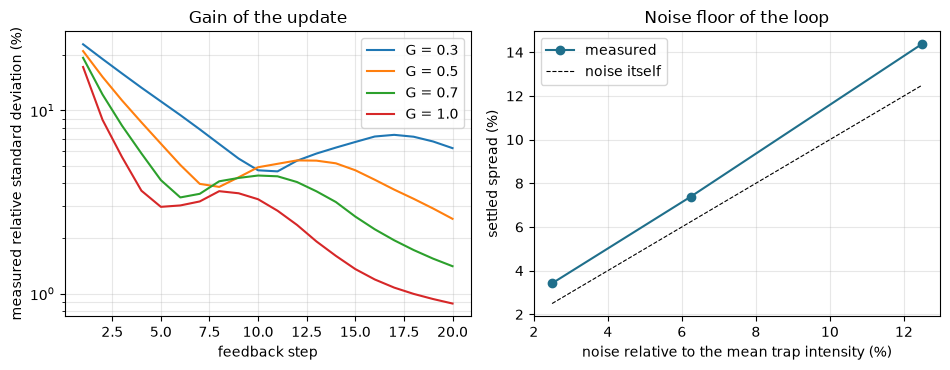

In [12]:
# left: the curve for each gain; right: the spread the loop settles at against the noise of the camera
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.8))
for gain, res in sorted(by_gain.items()):
    a.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=f"G = {gain}")
a.set_xlabel("feedback step")
a.set_ylabel("measured relative standard deviation (%)")
a.set_title("Gain of the update")
a.legend()
a.grid(True, which="both", alpha=0.3)
relative = [v[0] for v in floor.values()]
settled = [v[1] for v in floor.values()]
b.plot(relative, settled, "o-", color="#1f6f8b", label="measured")
b.plot(relative, relative, "k--", linewidth=0.8, label="noise itself")
b.set_xlabel("noise relative to the mean trap intensity (%)")
b.set_ylabel("settled spread (%)")
b.set_title("Noise floor of the loop")
b.legend()
b.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The loop settles at a spread that follows the noise of the camera and cannot go below it: 3.42 percent for a noise of 2.5 percent of the mean trap, 7.38 for 6.2 and 14.36 for 12.5, a little above the noise itself in every case (the measured value is 1.1 to 1.4 times the noise relative to the mean trap). That is the physical limit of any feedback on a noisy camera, since a trap cannot be made more uniform than it can be measured, and it is the dependence the emulator makes cheap to read: a hardware run would need three cameras. In the left panel the curves differ in speed and not in shape, and the Kim end point of three steps is out of reach of every gain tried for the Nogrette loop. The figure does not show noise that changes from one frame to the next in a correlated way, or a gain error that drifts between steps, either of which a real camera has; the emulator's noise is independent at each frame and its gain is fixed.

## Results

**Answer:** Both published updates take a hologram that the camera reports as 19 percent uneven to the published end points on the emulated camera, and the best open-loop hologram cannot. At a gain of 0.7 the spread reported on three camera draws falls from 19.46, 18.25 and 19.24 percent to 1.41, 1.03 and 0.95 percent in 20 iterations, against the published 1.4 percent; the update of Kim et al., from a plain GS start, reaches 1.12, 1.26 and 1.70 percent in three steps against the published 1.59, where the Nogrette loop has 8.26, 6.89 and 6.65 percent. The agreement is of the end points only, and the open-loop 19 percent was set from the paper. The phase-fixed WGS hologram M07, equal to 0.01 percent in the model, is read as 19.41 percent by the same camera. The loop is sensitive to the algorithm inside it (with three inner iterations the Nogrette loop ends at 5.23 percent instead of 1.41), to the gain (6.22, 2.56, 1.41 and 0.88 percent at step 20 for G = 0.3, 0.5, 0.7 and 1.0) and to the noise, below which it cannot go (3.42, 7.38 and 14.36 percent for noise of 2.5, 6.2 and 12.5 percent of the mean trap). The loops equalise the report, not the model: the model-side spread is about 19 percent at step 20.

What the notebook did not run is slmsuite's feedback mode, a real camera, or correlated noise.

## Summary

- The emulated camera reports a hologram that is uniform in the model as 19.46 percent uneven, because each trap has a fixed log-normal gain.
- The update of Nogrette et al. reaches 1.41, 1.03 and 0.95 percent at step 20 on three draws, at or below the published 1.4 percent; the update of Kim et al. reaches 1.12, 1.26 and 1.70 percent in three steps.
- The agreement is for end points, and the starting spread was set from the paper.
- Three inner Gerchberg-Saxton iterations between measurements make the Nogrette loop worse; the gain of the update sets its speed and the noise of the camera its floor.
- The loops equalise the report and not the model.

## References

- Nogrette et al. (2014). Single-atom trapping in holographic 2D arrays of microtraps with arbitrary geometries. Physical Review X 4, 021034. https://arxiv.org/abs/1402.5329
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178